# NinaPro DB7: EDA and Signal Analysis

**Scope.** (1) data integrity audit, (2) label and protocol analysis, (3) signal quality, time and
frequency analysis, (4) preprocessing with before/after evidence, (5) windowing, (6) feature-space and
variability analysis, (7) a **fixed experimental protocol** (split manifest + config) for fair comparison
with published work, and (8) small sanity baselines run under that protocol.

**How to run.** Set `DB7_ROOT` (environment variable) or keep the data in one of the auto-detected
folders. Files must be named `S<subject>_E<exercise>_A1.mat`. Every subject found is audited;
add subjects to the folder (or attach the full dataset on Kaggle) and **Run All** to extend the results.

**Reading the numbers.** The saved outputs state which subjects were available. Results computed from a
subset of subjects describe that subset only and are **not** DB7 cohort results.

In [1]:
import os, re, gc, json, math, time, hashlib, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import io, signal, stats
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sklearn
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)

## 0. Configuration

In [2]:
def find_data_root():
    candidates = []
    if os.environ.get('DB7_ROOT'):
        candidates.append(Path(os.environ['DB7_ROOT']))
    here = Path.cwd()
    for base in [here, *here.parents][:4]:
        candidates += [base / 'NinaPro_DB' / 'DB7', base / 'DB7', base / 'data' / 'DB7']
    candidates.append(Path('/kaggle/input'))
    for c in candidates:
        if c.is_dir() and next(c.rglob('S*_E*_A*.mat'), None) is not None:
            return c
    raise FileNotFoundError('No DB7 .mat files found. Set the DB7_ROOT environment variable.')

DATA_ROOT = find_data_root()
OUT = Path('/kaggle/working/DB7_Analysis') if Path('/kaggle/working').is_dir() else Path.cwd()
FIG_DIR, RES_DIR = OUT / 'figures', OUT / 'results'
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

FS = 2000                      # Hz, rate of the released synchronized files
N_EMG, N_ELEC = 12, 12
N_CLASSES = 41                 # rest (0) + 40 movements
REPS = (1, 2, 3, 4, 5, 6)

# Fixed experimental settings (frozen here, exported in section 7)
P = dict(
    train_reps=(1, 3, 4, 6), test_reps=(2, 5), dev_train_reps=(1, 3, 4), val_reps=(6,),
    window_ms=200, stride_ms=10,
    emg_band=(20.0, 450.0), emg_order=4, notch_hz=50.0, notch_q=30.0,
    imu_lowpass_hz=20.0, imu_order=2, zc_ssc_threshold=1e-8,
    seeds=(42, 137, 2026),
)

# Chart style: validated categorical order, one-hue sequential ramp, blue/gray/red diverging ramp
C = dict(blue='#2a78d6', orange='#eb6834', aqua='#1baf7a', yellow='#eda100',
         gray='#b8b7b2', ink='#0b0b0b', ink2='#52514e', grid='#e4e3df')
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#f3f7fd', '#9cc3ee', '#2a78d6', '#0c2f5c'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#8db8ea', '#efeeea', '#ee9a98', '#b52f2e'])
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 160, 'font.size': 9, 'axes.titlesize': 10, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c9c8c3',
    'axes.grid': True, 'grid.color': C['grid'], 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'text.color': C['ink'], 'axes.labelcolor': C['ink2'], 'xtick.color': C['ink2'], 'ytick.color': C['ink2'],
    'legend.frameon': False, 'lines.linewidth': 1.2,
})

def savefig(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()

def savetab(df, name, index=False):
    df.to_csv(RES_DIR / f'{name}.csv', index=index)
    return df

SUMMARY = {}  # headline numbers, written to results/summary.json at the end

print('Data root :', DATA_ROOT.name, '| outputs:', OUT.name)
print('Versions  : python', platform.python_version(), '| numpy', np.__version__, '| scipy', scipy.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)

Data root : DB7 | outputs: DB7_Analysis
Versions  : python 3.12.15 | numpy 2.5.5 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 1. File discovery and integrity audit

Identity is taken from the file name; the embedded `subject` / `exercise` values are checked against it.

In [3]:
def discover(root):
    found = {}
    for p in sorted(Path(root).rglob('*.mat')):
        m = re.fullmatch(r'S(\d+)_E(\d+)_A(\d+)\.mat', p.name)
        if m:
            key = (int(m.group(1)), int(m.group(2)))
            if key in found:
                raise ValueError(f'Duplicate recording {key}: point DB7_ROOT at one copy of DB7.')
            found[key] = p
    return found

def load(path, *names):
    d = io.loadmat(str(path), variable_names=list(names))
    return [d[n] for n in names]

def load_labels(path):
    lab, rep = load(path, 'restimulus', 'rerepetition')
    return lab.ravel().astype(np.int16), rep.ravel().astype(np.int16)

def segments(lab, rep):
    """Contiguous runs of constant (label, repetition). Returns [start, end, label, rep]."""
    cut = np.r_[0, 1 + np.flatnonzero((np.diff(lab) != 0) | (np.diff(rep) != 0)), len(lab)]
    return np.array([[a, b, lab[a], rep[a]] for a, b in zip(cut[:-1], cut[1:])], dtype=np.int64)

FILES = discover(DATA_ROOT)
SUBJECTS = sorted({s for s, _ in FILES})
DETAIL = SUBJECTS[0]           # subject used for the detailed single-subject figures
print(f'{len(FILES)} recordings, {len(SUBJECTS)} subject(s) available: {SUBJECTS}')
print(f'Detailed figures use subject {DETAIL}.')

2 recordings, 1 subject(s) available: [1]
Detailed figures use subject 1.


In [4]:
audit = []
for (sid, ex), path in sorted(FILES.items()):
    shapes = {n: (shape, dtype) for n, shape, dtype in io.whosmat(str(path))}
    meta = io.loadmat(str(path), variable_names=['subject', 'exercise'])
    lab, rep = load_labels(path)
    n_bad = 0
    for key in ('emg', 'acc', 'gyro', 'mag'):
        if key in shapes:
            x = load(path, key)[0]
            n_bad += int((~np.isfinite(x)).sum())
            del x; gc.collect()
    act = np.unique(lab[lab > 0])
    reps_ok = all(set(np.unique(rep[lab == c])) == set(REPS) for c in act)
    audit.append(dict(
        subject=sid, exercise=ex, MB=round(path.stat().st_size / 1e6, 1), samples=len(lab),
        minutes=round(len(lab) / FS / 60, 2),
        emg_ch=shapes['emg'][0][1], acc_ch=shapes.get('acc', ((0, 0),))[0][1],
        gyro_ch=shapes.get('gyro', ((0, 0),))[0][1], mag_ch=shapes.get('mag', ((0, 0),))[0][1],
        glove_ch=shapes.get('glove', ((0, 0),))[0][1],
        mat_subject=int(meta['subject'].item()) if 'subject' in meta else None,
        mat_exercise=int(meta['exercise'].item()) if 'exercise' in meta else None,
        movements=len(act), label_range=f'{act.min()}-{act.max()}', all_6_reps=reps_ok, nonfinite=n_bad,
        rest_pct=round(100 * float((lab == 0).mean()), 1)))
audit = savetab(pd.DataFrame(audit), 'integrity_audit')
display(audit.T)
mism = audit[(audit.mat_subject != audit.subject) | (audit.mat_exercise != audit.exercise)]
print('Filename / embedded-metadata mismatches:', 'none' if mism.empty else mism[['subject', 'exercise', 'mat_subject', 'mat_exercise']].values.tolist())
print('Variables in the first file:', [n for n, _, _ in io.whosmat(str(FILES[min(FILES)]))])

# Global class IDs: the released files already number exercise 1 as 1-17 and exercise 2 as 18-40.
for sid in SUBJECTS:
    ids = []
    for ex in (1, 2):
        if (sid, ex) in FILES:
            lab, _ = load_labels(FILES[(sid, ex)])
            ids.append(set(np.unique(lab[lab > 0]).tolist()))
    if len(ids) == 2:
        assert not (ids[0] & ids[1]), f'S{sid}: exercise label ranges overlap; remap before use'
SUMMARY.update(subjects_available=SUBJECTS, recordings=len(FILES), minutes_total=float(audit.minutes.sum()),
               samples_total=int(audit.samples.sum()), nonfinite=int(audit.nonfinite.sum()))

,0,1
subject,1,1
exercise,1,2
MB,624.1,885.8
samples,1797052,2530390
minutes,14.98,21.09
emg_ch,12,12
acc_ch,36,36
gyro_ch,36,36
mag_ch,36,36
glove_ch,18,18


Filename / embedded-metadata mismatches: none
Variables in the first file: ['subject', 'exercise', 'emg', 'acc', 'gyro', 'mag', 'stimulus', 'glove', 'repetition', 'restimulus', 'rerepetition']


## 2. Dataset description (published facts)

Source: [official DB7 page](https://ninapro.hevs.ch/instructions/DB7.html) and
[Krasoulis et al. 2017](https://doi.org/10.1186/s12984-017-0284-4).

In [5]:
facts = pd.DataFrame([
    ('Participants', '22: 20 intact (S1-S20) + 2 right transradial amputees (S21, S22)'),
    ('Intact cohort', 'age 22-33 y, 16 right-handed / 4 left-handed (S1, S4, S5, S14)'),
    ('Amputees', 'S21: 28 y, accident, 6 y since amputation; S22: 54 y, cancer, 18 y; both 50 % forearm remaining'),
    ('Sensors', '12 Delsys Trigno IM units: sEMG + 3-axis accelerometer, gyroscope, magnetometer'),
    ('Placement', '8 equally spaced around the forearm, 2 on flexor/extensor digitorum, 2 on biceps/triceps'),
    ('Native sampling', 'sEMG 2 kHz; inertial 128 Hz (released synchronized to the sEMG time base)'),
    ('Glove', 'CyberGlove II, 18 DOF (uncalibrated; not used as a classifier input)'),
    ('Movements', '40 + rest; Exercise 1: 17 finger/wrist, Exercise 2: 23 grasp/functional'),
    ('Repetitions', '6 per movement, nominally 5 s movement + 3 s rest'),
    ('Known exception', 'S21 did not perform the last 2 movements (38 classes without rest)'),
], columns=['item', 'value'])
savetab(facts, 'dataset_facts')
display(facts)

,item,value
0,Participants,22: 20 intact (S1-S20) + 2 right transradial a...
1,Intact cohort,"age 22-33 y, 16 right-handed / 4 left-handed (..."
2,Amputees,"S21: 28 y, accident, 6 y since amputation; S22..."
3,Sensors,12 Delsys Trigno IM units: sEMG + 3-axis accel...
4,Placement,"8 equally spaced around the forearm, 2 on flex..."
5,Native sampling,sEMG 2 kHz; inertial 128 Hz (released synchron...
6,Glove,"CyberGlove II, 18 DOF (uncalibrated; not used ..."
7,Movements,"40 + rest; Exercise 1: 17 finger/wrist, Exerci..."
8,Repetitions,"6 per movement, nominally 5 s movement + 3 s rest"
9,Known exception,S21 did not perform the last 2 movements (38 c...


## 3. Labels and acquisition protocol

`stimulus` is the on-screen cue; `restimulus` is the label re-aligned to the actual movement.
All experiments use `restimulus` / `rerepetition`.

In [6]:
seg_rows, lag_rows = [], []
for (sid, ex), path in sorted(FILES.items()):
    lab, rep, stim, srep = [v.ravel().astype(np.int16) for v in load(path, 'restimulus', 'rerepetition', 'stimulus', 'repetition')]
    for a, b, y, r in segments(lab, rep):
        seg_rows.append((sid, ex, a, b, y, r))
    cue = {(y, r): (a, b) for a, b, y, r in segments(stim, srep) if y > 0}
    for a, b, y, r in segments(lab, rep):
        if y > 0 and (y, r) in cue:
            ca, cb = cue[(y, r)]
            lag_rows.append(dict(subject=sid, exercise=ex, label=int(y), rep=int(r),
                                 onset_lag_s=(a - ca) / FS, offset_lag_s=(b - cb) / FS,
                                 cue_s=(cb - ca) / FS, refined_s=(b - a) / FS))
    audit.loc[(audit.subject == sid) & (audit.exercise == ex), 'label_disagreement_pct'] = round(100 * float((lab != stim).mean()), 2)
SEG = pd.DataFrame(seg_rows, columns=['subject', 'exercise', 'start', 'end', 'label', 'rep'])
SEG['dur_s'] = (SEG.end - SEG.start) / FS
LAG = savetab(pd.DataFrame(lag_rows), 'label_alignment_per_repetition')

dur = pd.DataFrame({
    'rest': SEG[(SEG.label == 0) & (SEG.rep > 0)].dur_s.describe(),
    'movement (refined)': SEG[SEG.label > 0].dur_s.describe(),
    'movement (cue)': LAG.cue_s.describe()}).round(2)
display(savetab(dur, 'segment_durations', index=True))
display(savetab(LAG[['onset_lag_s', 'offset_lag_s']].describe().round(3), 'label_lag_summary', index=True))
display(audit[['subject', 'exercise', 'rest_pct', 'label_disagreement_pct']])
display(savetab(LAG.groupby('exercise')[['onset_lag_s', 'offset_lag_s', 'refined_s']].median().round(3), 'label_lag_by_exercise', index=True))
bound = (LAG.onset_lag_s < 0.05) & (LAG.offset_lag_s > 0.9)
print(f'{int(bound.sum())} of {len(LAG)} repetitions have refined onset = cue onset AND refined offset about 1 s after the cue offset.')
print('This looks like a limit of the relabelling search window (an inference); inspect them before onset-timing studies.')
SUMMARY.update(lag_boundary_reps=int(bound.sum()), lag_reps=int(len(LAG)),
               lag_by_exercise={int(k): float(v) for k, v in LAG.groupby('exercise').onset_lag_s.median().items()})
SUMMARY.update(onset_lag_median_s=float(LAG.onset_lag_s.median()),
               onset_lag_iqr_s=[float(LAG.onset_lag_s.quantile(.25)), float(LAG.onset_lag_s.quantile(.75))],
               offset_lag_median_s=float(LAG.offset_lag_s.median()),
               move_dur_median_s=float(SEG[SEG.label > 0].dur_s.median()),
               move_dur_min_s=float(SEG[SEG.label > 0].dur_s.min()), move_dur_max_s=float(SEG[SEG.label > 0].dur_s.max()),
               rest_pct=float(100 * SEG[SEG.label == 0].dur_s.sum() / SEG.dur_s.sum()),
               label_disagreement_pct=float(np.average(audit.label_disagreement_pct, weights=audit.samples)))

,rest,movement (refined),movement (cue)
count,240.00,240.00,240.00
mean,4.76,4.25,5.42
std,1.50,1.32,0.08
min,2.36,1.90,5.31
25%,3.68,3.24,5.34
50%,4.97,3.89,5.43
75%,5.74,5.17,5.51
max,9.84,6.57,5.63


,onset_lag_s,offset_lag_s
count,240.000,240.000
mean,0.700,-0.471
std,0.482,0.993
min,0.006,-2.197
25%,0.274,-1.204
50%,0.751,-0.641
75%,0.986,0.434
max,2.496,0.994


,subject,exercise,rest_pct,label_disagreement_pct
0,1,1,59.1,23.89
1,1,2,48.5,14.68


,onset_lag_s,offset_lag_s,refined_s
exercise,,,
1,0.931,-1.108,3.377
2,0.661,-0.175,4.602


43 of 240 repetitions have refined onset = cue onset AND refined offset about 1 s after the cue offset.
This looks like a limit of the relabelling search window (an inference); inspect them before onset-timing studies.


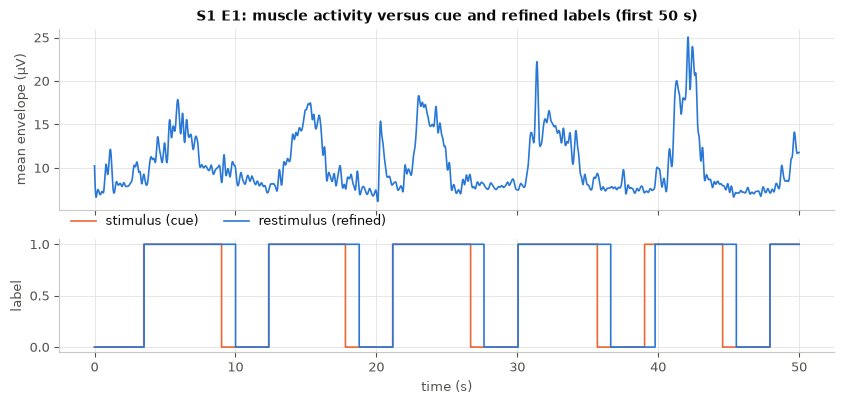

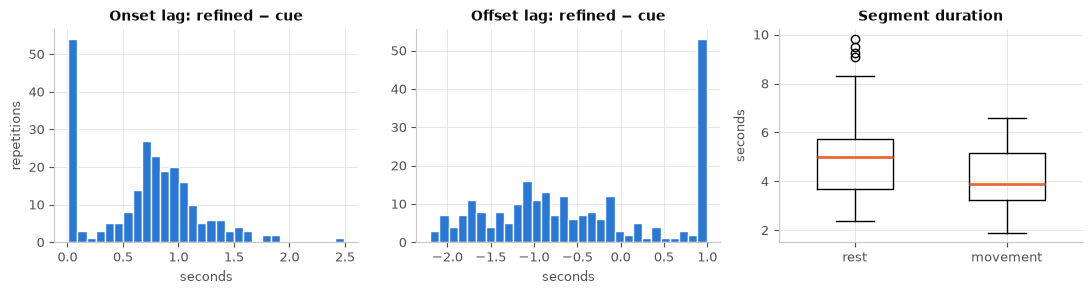

In [7]:
path = FILES[(DETAIL, 1)]
emg, stim = load(path, 'emg', 'stimulus'); stim = stim.ravel()
lab, rep = load_labels(path)
n = 50 * FS
t = np.arange(n) / FS
env = signal.sosfiltfilt(signal.butter(4, 4, fs=FS, output='sos'), np.abs(emg[:n]), axis=0).mean(axis=1)
fig, ax = plt.subplots(2, 1, figsize=(10, 4.2), sharex=True, gridspec_kw={'height_ratios': [1.6, 1]})
ax[0].plot(t, env * 1e6, color=C['blue']); ax[0].set_ylabel('mean envelope (µV)')
ax[0].set_title(f'S{DETAIL} E1: muscle activity versus cue and refined labels (first 50 s)')
ax[1].step(t, stim[:n], where='post', color=C['orange'], label='stimulus (cue)')
ax[1].step(t, lab[:n], where='post', color=C['blue'], label='restimulus (refined)')
ax[1].set_ylabel('label'); ax[1].set_xlabel('time (s)'); ax[1].legend(ncol=2, loc='lower left', bbox_to_anchor=(0, 1.0))
savefig(fig, 'fig01_labels_timeline')
del emg; gc.collect()

fig, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].hist(LAG.onset_lag_s, bins=30, color=C['blue'], edgecolor='white')
ax[0].set(title='Onset lag: refined − cue', xlabel='seconds', ylabel='repetitions')
ax[1].hist(LAG.offset_lag_s, bins=30, color=C['blue'], edgecolor='white')
ax[1].set(title='Offset lag: refined − cue', xlabel='seconds')
ax[2].boxplot([SEG[(SEG.label == 0) & (SEG.rep > 0)].dur_s, SEG[SEG.label > 0].dur_s], widths=.5,
              medianprops=dict(color=C['orange'], linewidth=2))
ax[2].set_xticks([1, 2], ['rest', 'movement']); ax[2].set(title='Segment duration', ylabel='seconds')
fig.tight_layout(); savefig(fig, 'fig02_label_lag_durations')

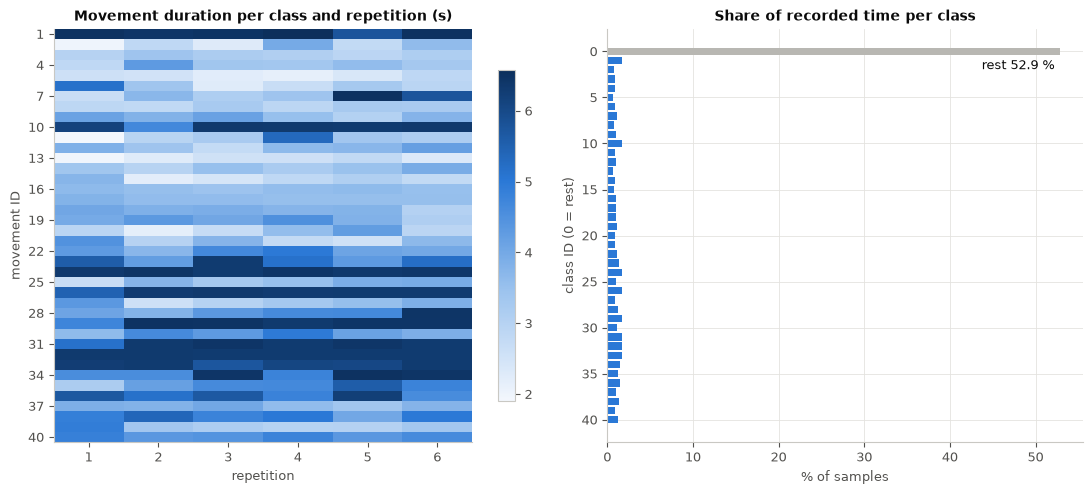

Rest = 52.9 % of samples; movements range 0.67-1.77 % each.


In [8]:
act = SEG[SEG.label > 0]
mat = act.groupby(['label', 'rep']).dur_s.sum().unstack('rep') / max(1, len(SUBJECTS))
share = SEG.groupby('label').dur_s.sum(); share = 100 * share / share.sum()
fig, ax = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={'width_ratios': [1.1, 1]})
im = ax[0].imshow(mat.values, aspect='auto', cmap=SEQ)
ax[0].set_xticks(range(6), mat.columns); ax[0].set_yticks(range(0, len(mat), 3), mat.index[::3])
ax[0].set(title='Movement duration per class and repetition (s)', xlabel='repetition', ylabel='movement ID'); ax[0].grid(False)
fig.colorbar(im, ax=ax[0], shrink=.8)
ax[1].barh(share.index, share.values, color=[C['gray'] if i == 0 else C['blue'] for i in share.index])
ax[1].set(title='Share of recorded time per class', xlabel='% of samples', ylabel='class ID (0 = rest)'); ax[1].invert_yaxis()
ax[1].annotate(f'rest {share.loc[0]:.1f} %', (share.loc[0], 0), ha='right', va='top', color=C['ink'], xytext=(-4, -6), textcoords='offset points')
fig.tight_layout(); savefig(fig, 'fig03_class_balance')
mv = share.drop(0)
SUMMARY.update(class_share_move_min=float(mv.min()), class_share_move_max=float(mv.max()),
               imbalance_rest_to_mean_move=float(share.loc[0] / mv.mean()))
print(f'Rest = {share.loc[0]:.1f} % of samples; movements range {mv.min():.2f}-{mv.max():.2f} % each.')

## 4. Raw signals

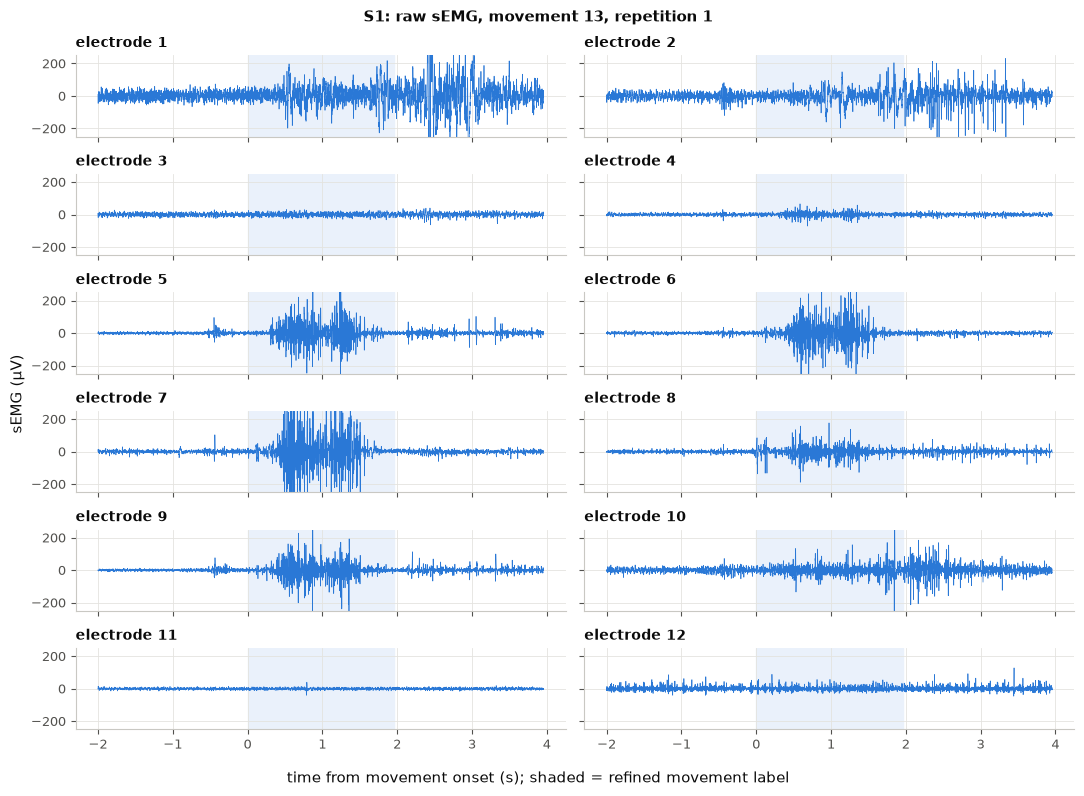

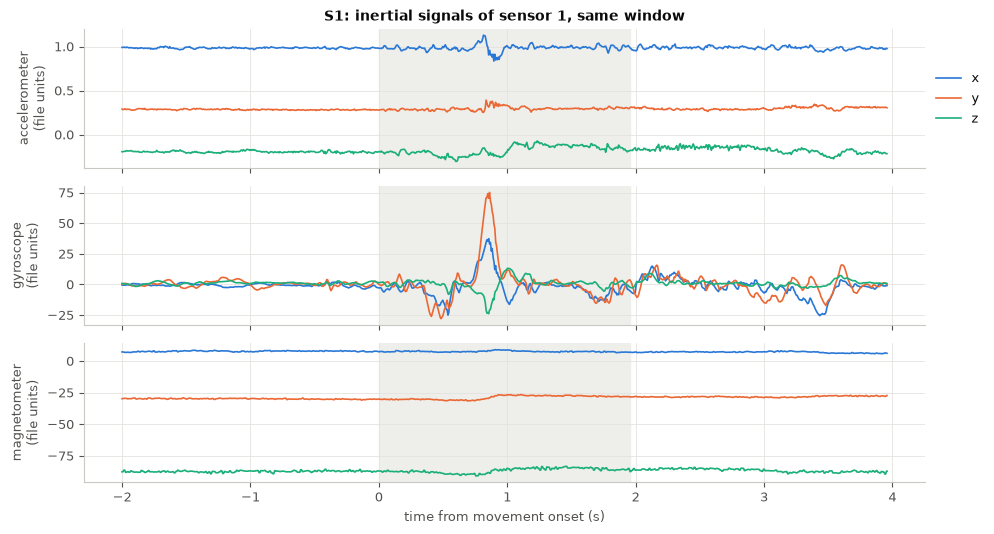

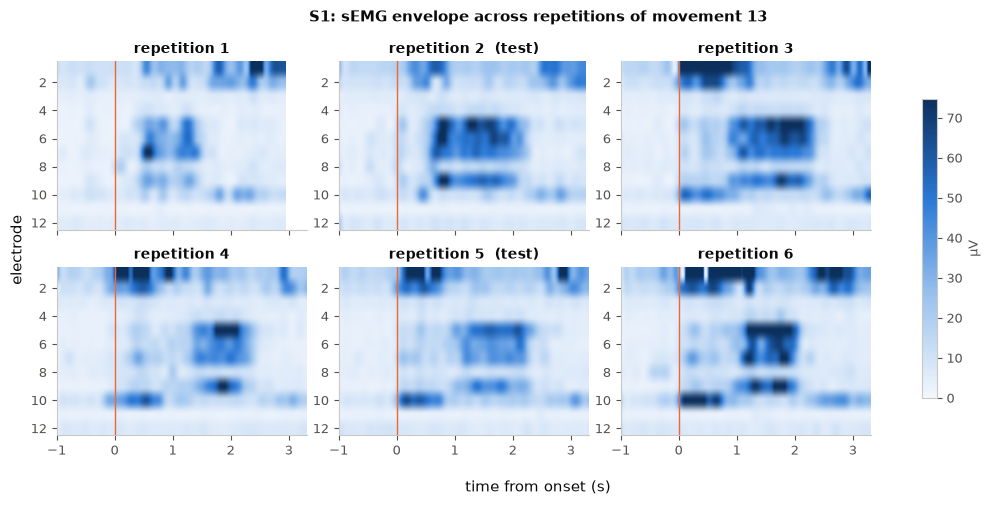

In [9]:
path = FILES[(DETAIL, 1)]
emg, acc, gyro, mag = load(path, 'emg', 'acc', 'gyro', 'mag')
lab, rep = load_labels(path)
sg = segments(lab, rep)
show_class = 13
a, b = sg[(sg[:, 2] == show_class) & (sg[:, 3] == 1)][0][:2]
lo, hi = a - 2 * FS, b + 2 * FS
t = (np.arange(lo, hi) - a) / FS
lim = np.percentile(np.abs(emg[lo:hi]), 99.8) * 1e6
fig, ax = plt.subplots(6, 2, figsize=(11, 8), sharex=True, sharey=True)
for ch, axis in enumerate(ax.ravel()):
    axis.axvspan(0, (b - a) / FS, color='#eaf1fb', zorder=0)
    axis.plot(t, emg[lo:hi, ch] * 1e6, color=C['blue'], linewidth=.5)
    axis.set_title(f'electrode {ch + 1}', loc='left'); axis.set_ylim(-lim, lim)
fig.supxlabel('time from movement onset (s); shaded = refined movement label'); fig.supylabel('sEMG (µV)')
fig.suptitle(f'S{DETAIL}: raw sEMG, movement {show_class}, repetition 1', fontweight='bold')
fig.tight_layout(); savefig(fig, 'fig04_raw_emg_12ch')

fig, ax = plt.subplots(3, 1, figsize=(10, 5.4), sharex=True)
for axis, (name, x) in zip(ax, [('accelerometer', acc), ('gyroscope', gyro), ('magnetometer', mag)]):
    axis.axvspan(0, (b - a) / FS, color='#eeeeea', zorder=0)
    for k, (lbl, col) in enumerate(zip('xyz', [C['blue'], C['orange'], C['aqua']])):
        axis.plot(t, x[lo:hi, k], color=col, label=lbl)
    axis.set_ylabel(name + '\n(file units)')
ax[0].legend(ncol=1, loc='center left', bbox_to_anchor=(1.0, .5)); ax[0].set_title(f'S{DETAIL}: inertial signals of sensor 1, same window')
ax[-1].set_xlabel('time from movement onset (s)')
fig.tight_layout(); savefig(fig, 'fig05_raw_imu')

env_sos = signal.butter(4, 4, fs=FS, output='sos')
fig, ax = plt.subplots(2, 3, figsize=(11, 5), sharex=True)
for axis, r in zip(ax.ravel(), REPS):
    a, b = sg[(sg[:, 2] == show_class) & (sg[:, 3] == r)][0][:2]
    e = signal.sosfiltfilt(env_sos, np.abs(emg[a - FS:b + FS]), axis=0) * 1e6
    im = axis.imshow(e.T, aspect='auto', cmap=SEQ, extent=[-1, (b - a) / FS + 1, 12.5, .5],
                     vmin=0, vmax=np.percentile(np.abs(emg[sg[sg[:, 2] == show_class][0][0]:b]) * 1e6, 97))
    axis.set_title(f'repetition {r}' + ('  (test)' if r in P['test_reps'] else '')); axis.grid(False)
    axis.axvline(0, color=C['orange'], lw=1)
fig.supxlabel('time from onset (s)'); fig.supylabel('electrode')
fig.suptitle(f'S{DETAIL}: sEMG envelope across repetitions of movement {show_class}', fontweight='bold')
fig.tight_layout(); fig.colorbar(im, ax=ax, label='µV', shrink=.8); savefig(fig, 'fig06_repetition_consistency')
del emg, acc, gyro, mag; gc.collect()

## 5. Signal quality

Amplitude statistics, activation SNR (movement RMS / rest RMS), saturation, flat runs and kurtosis,
per electrode on the **raw** signal.

,rest_rms_uV,move_rms_uV,snr_dB,at_extreme_pct,flat_pct,kurtosis
electrode,,,,,,
1,24.753,97.177,10.378,0.0,0.0,314.249
2,17.758,54.961,9.474,0.0,0.0,52.350
3,8.390,13.732,4.272,0.0,0.0,23.943
4,5.097,8.424,4.284,0.0,0.0,9.326
5,4.763,16.086,9.444,0.0,0.0,85.182
6,5.271,17.908,10.477,0.0,0.0,49.822
7,6.675,25.232,10.960,0.0,0.0,70.836
8,10.871,43.824,12.075,0.0,0.0,178.223
9,5.000,17.867,10.579,0.0,0.0,54.813


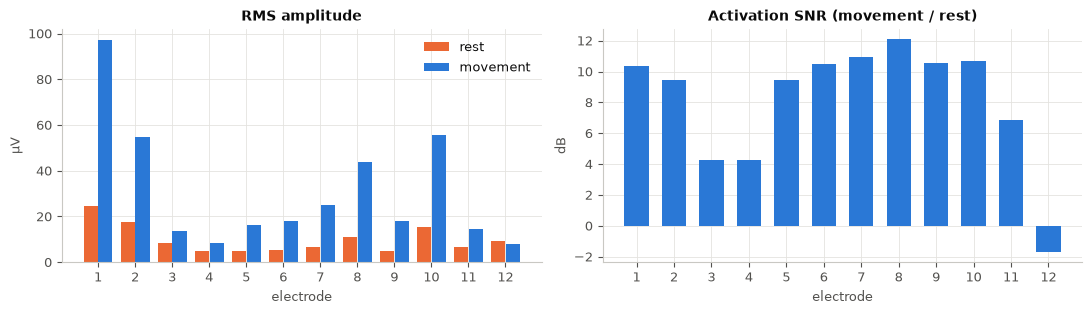

In [10]:
q_rows = []
for (sid, ex), path in sorted(FILES.items()):
    emg = load(path, 'emg')[0]; lab, rep = load_labels(path)
    for ch in range(N_EMG):
        x = emg[:, ch].astype(np.float64)
        rest, move = x[(lab == 0)], x[lab > 0]
        rr, mr = np.sqrt(np.mean((rest - rest.mean()) ** 2)), np.sqrt(np.mean((move - move.mean()) ** 2))
        flat = np.diff(x) == 0
        q_rows.append(dict(subject=sid, exercise=ex, electrode=ch + 1, mean_uV=x.mean() * 1e6,
                           min_mV=x.min() * 1e3, max_mV=x.max() * 1e3, rest_rms_uV=rr * 1e6, move_rms_uV=mr * 1e6,
                           snr_dB=20 * np.log10(mr / rr),
                           at_extreme_pct=100 * np.mean((x == x.max()) | (x == x.min())),
                           flat_pct=100 * np.mean(flat), kurtosis=stats.kurtosis(x)))
    del emg; gc.collect()
Q = savetab(pd.DataFrame(q_rows), 'signal_quality_by_channel')
qs = Q.groupby('electrode')[['rest_rms_uV', 'move_rms_uV', 'snr_dB', 'at_extreme_pct', 'flat_pct', 'kurtosis']].mean().round(4)
display(savetab(qs, 'signal_quality_summary', index=True).round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
x = np.arange(1, 13)
ax[0].bar(x - .2, qs.rest_rms_uV, .38, color=C['orange'], label='rest')
ax[0].bar(x + .2, qs.move_rms_uV, .38, color=C['blue'], label='movement')
ax[0].set(title='RMS amplitude', xlabel='electrode', ylabel='µV', xticks=x); ax[0].legend()
ax[1].bar(x, qs.snr_dB, .65, color=C['blue']); ax[1].set(title='Activation SNR (movement / rest)', xlabel='electrode', ylabel='dB', xticks=x)
fig.tight_layout(); savefig(fig, 'fig07_signal_quality')
SUMMARY.update(snr_db_min=float(qs.snr_dB.min()), snr_db_max=float(qs.snr_dB.max()),
               snr_best_electrode=int(qs.snr_dB.idxmax()), snr_worst_electrode=int(qs.snr_dB.idxmin()),
               at_extreme_pct_max=float(Q.at_extreme_pct.max()), flat_pct_max=float(Q.flat_pct.max()),
               kurtosis_median=float(Q['kurtosis'].median()))

## 6. Frequency-domain analysis

In [11]:
def welch_segments(x, segs, nperseg=4096):
    """Length-weighted average of per-segment Welch PSDs (no artificial joins)."""
    acc_p, tot = 0, 0
    for a, b in segs[:, :2]:
        if b - a >= nperseg:
            f, p = signal.welch(x[a:b], FS, nperseg=nperseg, axis=0)
            acc_p = acc_p + p * (b - a); tot += b - a
    return f, acc_p / tot

def band_stats(f, p):
    tot = p.sum(0)
    cum = np.cumsum(p, 0) / tot
    return dict(pct_below_20=100 * p[f < 20].sum(0) / tot, pct_20_450=100 * p[(f >= 20) & (f <= 450)].sum(0) / tot,
                pct_above_450=100 * p[f > 450].sum(0) / tot,
                median_freq_Hz=np.array([f[np.searchsorted(cum[:, c], .5)] for c in range(p.shape[1])]),
                mean_freq_Hz=(f[:, None] * p).sum(0) / tot)

def line_ratio(f, p, f0):
    core = np.abs(f - f0) <= .6
    side = (np.abs(f - f0) > 2) & (np.abs(f - f0) <= 6)
    return p[core].mean(0) / np.median(p[side], axis=0)

spec_rows, line_rows, psd_keep = [], [], {}
for (sid, ex), path in sorted(FILES.items()):
    emg = load(path, 'emg')[0]; lab, rep = load_labels(path); sg = segments(lab, rep)
    for state, m in (('rest', sg[:, 2] == 0), ('movement', sg[:, 2] > 0)):
        f, p = welch_segments(emg, sg[m])
        if sid == DETAIL and ex == 1: psd_keep[state] = (f, p)
        bs = band_stats(f, p)
        for ch in range(N_EMG):
            spec_rows.append(dict(subject=sid, exercise=ex, state=state, electrode=ch + 1, **{k: v[ch] for k, v in bs.items()}))
        for f0 in (50, 100, 150, 250):
            r = line_ratio(f, p, f0)
            for ch in range(N_EMG):
                line_rows.append(dict(subject=sid, exercise=ex, state=state, electrode=ch + 1, freq=f0, peak_ratio=r[ch]))
    del emg; gc.collect()
SPEC = savetab(pd.DataFrame(spec_rows), 'spectral_by_channel')
LINE = savetab(pd.DataFrame(line_rows), 'powerline_peak_ratio')
display(SPEC.groupby('state')[['pct_below_20', 'pct_20_450', 'pct_above_450', 'median_freq_Hz', 'mean_freq_Hz']].mean().round(2))
lt = LINE.groupby(['freq', 'electrode']).peak_ratio.mean().unstack().round(2)
print('Peak power / neighbouring power (1 = no line peak):'); display(lt)

,pct_below_20,pct_20_450,pct_above_450,median_freq_Hz,mean_freq_Hz
state,,,,,
movement,5.26,93.78,0.96,81.26,105.10
rest,8.97,89.74,1.28,71.96,104.92


Peak power / neighbouring power (1 = no line peak):


electrode,1,2,3,4,5,6,7,8,9,10,11,12
freq,,,,,,,,,,,,
50,3.44,2.00,0.91,0.93,0.99,0.95,1.67,1.87,1.04,1.09,0.94,1.79
100,1.00,1.07,1.05,1.04,1.04,1.02,1.09,1.02,1.03,1.00,1.04,1.03
150,1.07,0.99,0.98,1.00,1.09,1.03,1.01,1.09,0.95,1.00,0.92,0.95
250,0.92,1.04,2.72,1.04,0.96,2.10,0.96,1.08,1.06,1.03,0.92,0.99


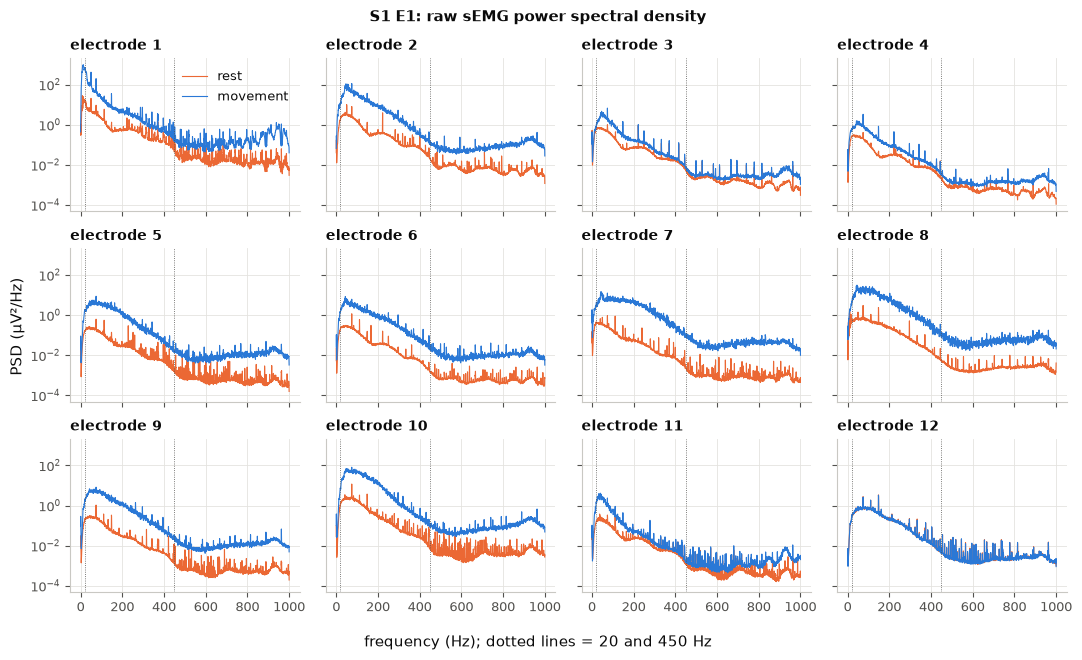

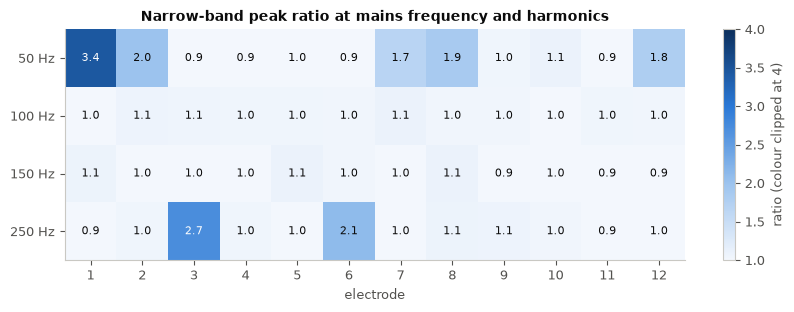

In [12]:
fig, ax = plt.subplots(3, 4, figsize=(11, 6.6), sharex=True, sharey=True)
for ch, axis in enumerate(ax.ravel()):
    for state, col in (('rest', C['orange']), ('movement', C['blue'])):
        f, p = psd_keep[state]
        axis.semilogy(f, p[:, ch] * 1e12, color=col, label=state, linewidth=.8)
    for edge in P['emg_band']: axis.axvline(edge, color=C['ink2'], lw=.6, ls=':')
    axis.set_title(f'electrode {ch + 1}', loc='left')
ax[0, 0].legend(); fig.supxlabel('frequency (Hz); dotted lines = 20 and 450 Hz'); fig.supylabel('PSD (µV²/Hz)')
fig.suptitle(f'S{DETAIL} E1: raw sEMG power spectral density', fontweight='bold')
fig.tight_layout(); savefig(fig, 'fig08_psd_rest_vs_movement')

fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(LINE.groupby(['freq', 'electrode']).peak_ratio.mean().unstack().values, cmap=SEQ, aspect='auto', vmin=1, vmax=4)
ax.set_xticks(range(12), range(1, 13)); ax.set_yticks(range(4), ['50 Hz', '100 Hz', '150 Hz', '250 Hz']); ax.grid(False)
for i in range(4):
    for j in range(12):
        v = lt.values[i, j]; ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=8, color='white' if v > 2.4 else C['ink'])
ax.set(title='Narrow-band peak ratio at mains frequency and harmonics', xlabel='electrode')
fig.colorbar(im, ax=ax, label='ratio (colour clipped at 4)'); savefig(fig, 'fig09_powerline_ratio')
SUMMARY.update(line50_ratio_median=float(LINE[LINE.freq == 50].groupby('electrode').peak_ratio.mean().median()),
               line50_ratio_max=float(LINE[LINE.freq == 50].groupby('electrode').peak_ratio.mean().max()),
               line50_electrodes_over_2=[int(i) for i, v in lt.loc[50].items() if v > 2],
               line250_electrodes_over_2=[int(i) for i, v in lt.loc[250].items() if v > 2],
               median_freq_move_Hz=float(SPEC[SPEC.state == 'movement'].median_freq_Hz.mean()),
               median_freq_rest_Hz=float(SPEC[SPEC.state == 'rest'].median_freq_Hz.mean()),
               pct_below20_move=float(SPEC[SPEC.state == 'movement'].pct_below_20.mean()),
               pct_below20_move_max_channel=float(SPEC[SPEC.state == 'movement'].groupby('electrode').pct_below_20.mean().max()),
               pct_inband_move=float(SPEC[SPEC.state == 'movement'].pct_20_450.mean()))

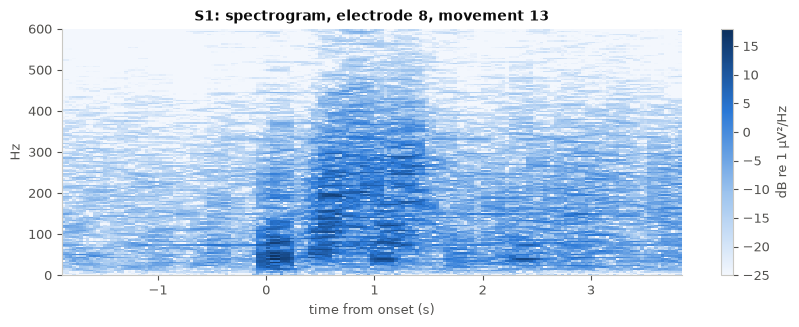

In [13]:
emg = load(FILES[(DETAIL, 1)], 'emg')[0]; lab, rep = load_labels(FILES[(DETAIL, 1)]); sg = segments(lab, rep)
ch = int(qs.snr_dB.idxmax()) - 1
a, b = sg[(sg[:, 2] == show_class) & (sg[:, 3] == 1)][0][:2]
f, tt, S = signal.spectrogram(emg[a - 2 * FS:b + 2 * FS, ch], FS, nperseg=512, noverlap=448)
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.pcolormesh(tt - 2, f, 10 * np.log10(S * 1e12 + 1e-6), cmap=SEQ, shading='auto', vmin=-25)
ax.set(ylim=(0, 600), title=f'S{DETAIL}: spectrogram, electrode {ch + 1}, movement {show_class}', xlabel='time from onset (s)', ylabel='Hz'); ax.grid(False)
fig.colorbar(im, ax=ax, label='dB re 1 µV²/Hz'); savefig(fig, 'fig10_spectrogram')
del emg; gc.collect()

### 6.1 Inertial channels: effective bandwidth

The inertial streams are stored on the 2 kHz time base but were sampled at 128 Hz, so power above 64 Hz
should be negligible and a windowed model gains no extra information from the 2 kHz storage rate.

In [14]:
imu_rows = []
for (sid, ex), path in sorted(FILES.items()):
    lab, rep = load_labels(path); sg = segments(lab, rep)
    for key in ('acc', 'gyro', 'mag'):
        x = load(path, key)[0]
        f, p = welch_segments(x, sg[sg[:, 2] > 0], nperseg=8192)
        d2 = np.abs(np.diff(x[:200000].astype(np.float64), 2, axis=0))
        scale = np.abs(np.diff(x[:200000].astype(np.float64), axis=0)).mean(0) + 1e-12
        imu_rows.append(dict(subject=sid, exercise=ex, modality=key,
                             pct_power_above_64Hz=100 * np.median(p[f > 64].sum(0) / p.sum(0)),
                             pct_near_linear_samples=100 * np.mean(d2 < 0.02 * scale),
                             minimum=float(x.min()), maximum=float(x.max())))
        del x; gc.collect()
IMU = savetab(pd.DataFrame(imu_rows), 'imu_bandwidth')
display(IMU.groupby('modality')[['pct_power_above_64Hz', 'pct_near_linear_samples', 'minimum', 'maximum']].mean().round(3))
SUMMARY.update(imu_pct_above64={k: float(v) for k, v in IMU.groupby('modality').pct_power_above_64Hz.mean().items()})

,pct_power_above_64Hz,pct_near_linear_samples,minimum,maximum
modality,,,,
acc,0.079,88.887,-2.000,1.848
gyro,0.009,89.152,-194.566,240.341
mag,0.025,89.404,-324.300,447.550


## 7. Preprocessing and fixed experimental settings

| Step | sEMG | Inertial |
|---|---|---|
| 1 | 4th-order Butterworth band-pass 20-450 Hz, zero phase | 2nd-order Butterworth low-pass 20 Hz, zero phase |
| 2 | 50 Hz notch (Q = 30) | none |
| 3 | windows of 200 ms, stride 10 ms, inside one (label, repetition) segment | same windows |
| 4 | features or raw tensor; z-score fitted on **training repetitions of that subject only** | same |

Filters have fixed coefficients (nothing is learned from data), so filtering the continuous recording
leaks no label or test statistics. Zero-phase filtering is non-causal: for a real-time claim replace
`sosfiltfilt` with `sosfilt` and report that result separately.

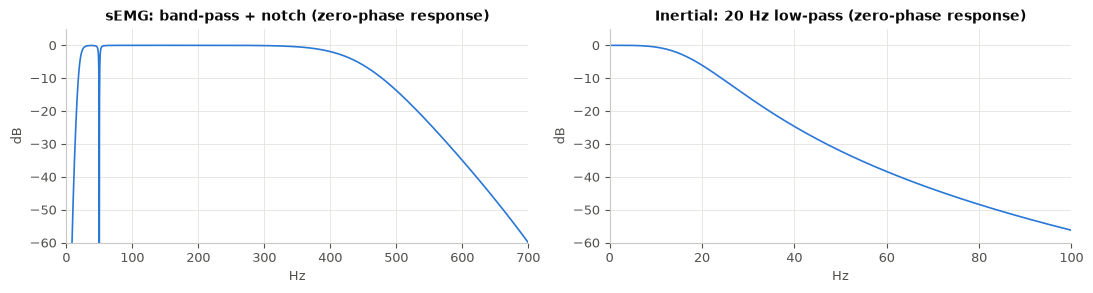

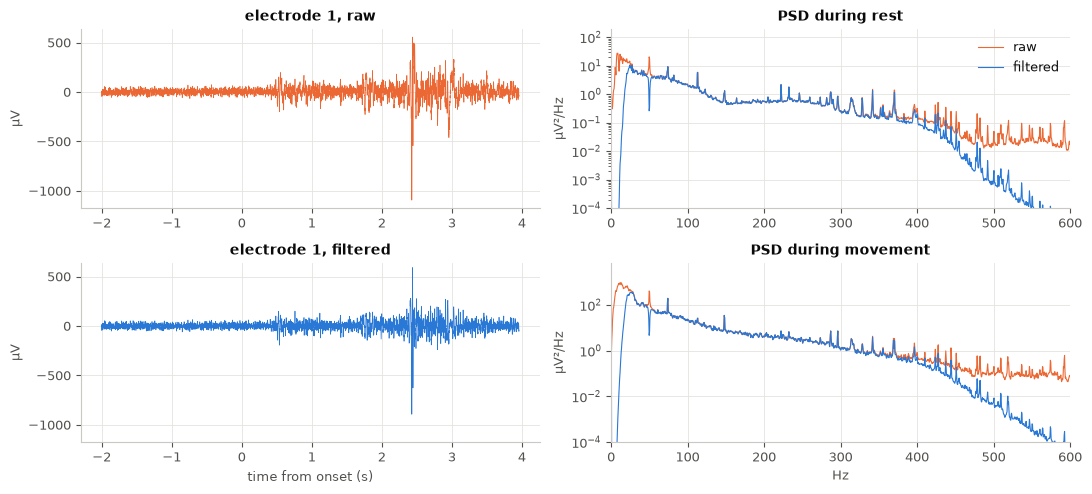

,electrode,line50_ratio_raw,line50_ratio_filtered,power_below20_raw_pct,power_below20_filtered_pct
0,1,4.001,0.075,28.502,1.049
1,2,3.001,0.050,3.858,0.207
2,3,0.989,0.042,7.218,0.352
3,4,0.975,0.041,7.292,0.380
4,5,0.985,0.043,4.294,0.230
5,6,1.048,0.042,4.595,0.235
6,7,2.094,0.051,8.197,0.386
7,8,2.029,0.046,6.903,0.190
8,9,1.154,0.045,4.092,0.224
9,10,1.168,0.044,2.054,0.129


In [15]:
SOS_EMG = signal.butter(P['emg_order'], P['emg_band'], btype='bandpass', fs=FS, output='sos')
b_n, a_n = signal.iirnotch(P['notch_hz'], P['notch_q'], fs=FS)
SOS_EMG_ALL = np.vstack([SOS_EMG, signal.tf2sos(b_n, a_n)])
SOS_IMU = signal.butter(P['imu_order'], P['imu_lowpass_hz'], btype='lowpass', fs=FS, output='sos')

def filter_columns(sos, x):
    out = np.empty_like(x, dtype=np.float32)
    for c in range(x.shape[1]):          # column-wise to keep memory low
        out[:, c] = signal.sosfiltfilt(sos, x[:, c].astype(np.float64))
    return out

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for axis, sos, ttl, xmax in ((ax[0], SOS_EMG_ALL, 'sEMG: band-pass + notch', 700), (ax[1], SOS_IMU, 'Inertial: 20 Hz low-pass', 100)):
    w, h = signal.sosfreqz(sos, worN=16384, fs=FS)
    axis.plot(w, 20 * np.log10(np.maximum(np.abs(h) ** 2, 1e-8)), color=C['blue'])  # squared: forward-backward
    axis.set(title=ttl + ' (zero-phase response)', xlabel='Hz', ylabel='dB', xlim=(0, xmax), ylim=(-60, 5))
fig.tight_layout(); savefig(fig, 'fig11_filter_response')

emg = load(FILES[(DETAIL, 1)], 'emg')[0]; lab, rep = load_labels(FILES[(DETAIL, 1)]); sg = segments(lab, rep)
filt = filter_columns(SOS_EMG_ALL, emg)
ch = 0
a, b = sg[(sg[:, 2] == show_class) & (sg[:, 3] == 1)][0][:2]; lo, hi = a - 2 * FS, b + 2 * FS
t = (np.arange(lo, hi) - a) / FS
fig, ax = plt.subplots(2, 2, figsize=(11, 5))
for axis, x, ttl, col in ((ax[0, 0], emg, 'raw', C['orange']), (ax[1, 0], filt, 'filtered', C['blue'])):
    axis.plot(t, x[lo:hi, ch] * 1e6, color=col, lw=.5); axis.set(title=f'electrode {ch + 1}, {ttl}', ylabel='µV')
ax[1, 0].set_xlabel('time from onset (s)'); ax[1, 0].set_ylim(ax[0, 0].get_ylim())
for axis, state, m in ((ax[0, 1], 'rest', sg[:, 2] == 0), (ax[1, 1], 'movement', sg[:, 2] > 0)):
    for x, lbl, col in ((emg, 'raw', C['orange']), (filt, 'filtered', C['blue'])):
        f, p = welch_segments(x, sg[m]); axis.semilogy(f, p[:, ch] * 1e12, color=col, label=lbl, lw=.8)
    axis.set(title=f'PSD during {state}', xlim=(0, 600), ylim=(1e-4, None), ylabel='µV²/Hz')
ax[0, 1].legend(); ax[1, 1].set_xlabel('Hz')
fig.tight_layout(); savefig(fig, 'fig12_before_after_filtering')

fr, pr = welch_segments(emg, sg[sg[:, 2] == 0]); _, pf = welch_segments(filt, sg[sg[:, 2] == 0])
effect = pd.DataFrame({'electrode': range(1, 13),
                       'line50_ratio_raw': line_ratio(fr, pr, 50), 'line50_ratio_filtered': line_ratio(fr, pf, 50),
                       'power_below20_raw_pct': 100 * pr[fr < 20].sum(0) / pr.sum(0),
                       'power_below20_filtered_pct': 100 * pf[fr < 20].sum(0) / pf.sum(0)}).round(3)
display(savetab(effect, 'preprocessing_effect'))
del emg, filt; gc.collect()

### 7.1 Windowing

A window is kept only if **every sample** has the same label and repetition. Transition windows are
therefore excluded, and no window can cross a train/test boundary.

In [16]:
def split_of(rep, dev=False):
    if rep in P['test_reps']: return 'test'
    if dev and rep in P['val_reps']: return 'val'
    return 'train' if rep in P['train_reps'] else 'unused'

def n_windows(length, win, stride):
    return np.maximum(0, (length - win) // stride + 1)

valid = SEG[SEG.rep.isin(REPS)].copy()
valid['split'] = [split_of(r, dev=True) for r in valid.rep]
grid = []
for win in (150, 200, 250):
    for stride in (10, 50, 100):
        k = n_windows(valid.end - valid.start, win * FS // 1000, stride * FS // 1000)
        g = valid.assign(k=k)
        row = dict(window_ms=win, stride_ms=stride)
        row.update({s: int(g[g.split == s].k.sum()) for s in ('train', 'val', 'test')})
        row['total'] = int(k.sum()); row['rest_pct'] = round(100 * g[g.label == 0].k.sum() / k.sum(), 1)
        grid.append(row)
grid = savetab(pd.DataFrame(grid), 'window_counts')
display(grid)
base = grid[(grid.window_ms == P['window_ms']) & (grid.stride_ms == P['stride_ms'])].iloc[0]
lost = SEG[~SEG.rep.isin(REPS)].dur_s.sum()
print(f'Excluded: {lost:.1f} s with repetition ID 0 (recording tails).')
SUMMARY.update(windows_train=int(base.train), windows_val=int(base.val), windows_test=int(base.test),
               windows_total=int(base.total), windows_rest_pct=float(base.rest_pct))

,window_ms,stride_ms,train,val,test,total,rest_pct
0,150,10,108031,34243,67061,209335,52.9
1,150,50,21704,6878,13475,42057,52.9
2,150,100,10911,3457,6777,21145,52.9
3,200,10,106831,33843,66261,206935,53.0
4,200,50,21464,6798,13315,41577,53.0
5,200,100,10793,3421,6698,20912,52.9
6,250,10,105631,33443,65461,204535,53.0
7,250,50,21224,6718,13155,41097,53.0
8,250,100,10671,3377,6617,20665,53.0


Excluded: 1.0 s with repetition ID 0 (recording tails).


## 8. Feature space and variability

In [17]:
FEATURE_SETS = ('emg', 'acc', 'gyro', 'mag')

def window_features(x, starts_rel, win, kind):
    """x: one segment [T, C]; returns [n_windows, n_features]."""
    v = np.lib.stride_tricks.sliding_window_view(x, win, axis=0)[starts_rel]      # [n, C, win]
    if kind != 'emg':
        return v.mean(axis=2)
    d = np.diff(v, axis=2); th = P['zc_ssc_threshold']
    mav = np.abs(v).mean(2); rms = np.sqrt((v * v).mean(2)); wl = np.abs(d).sum(2)
    zc = ((v[:, :, 1:] * v[:, :, :-1] < 0) & (np.abs(d) > th)).sum(2)
    ssc = ((d[:, :, 1:] * d[:, :, :-1] < 0) & ((np.abs(d[:, :, 1:]) > th) | (np.abs(d[:, :, :-1]) > th))).sum(2)
    return np.concatenate([np.log(mav + 1e-12), np.log(rms + 1e-12), np.log(wl + 1e-12), zc, ssc], axis=1)

def subject_features(sid, window_ms, stride_ms, kinds=FEATURE_SETS):
    """Filtered, windowed features of one subject plus window metadata."""
    win, step = window_ms * FS // 1000, stride_ms * FS // 1000
    feats = {k: [] for k in kinds}; meta = []
    for ex in (1, 2):
        if (sid, ex) not in FILES: continue
        path = FILES[(sid, ex)]; lab, rep = load_labels(path)
        sg = [s for s in segments(lab, rep) if s[3] in REPS and s[1] - s[0] >= win]
        for kind in kinds:
            x = filter_columns(SOS_EMG_ALL if kind == 'emg' else SOS_IMU, load(path, kind)[0])
            for a, b, y, r in sg:
                st = np.arange(0, b - a - win + 1, step)
                feats[kind].append(window_features(x[a:b], st, win, kind).astype(np.float32))
            del x; gc.collect()
        for a, b, y, r in sg:
            st = np.arange(0, b - a - win + 1, step) + a
            meta.append(np.column_stack([np.full(len(st), ex), np.full(len(st), y), np.full(len(st), r), st, np.full(len(st), a)]))
    feats = {k: np.vstack(v) for k, v in feats.items()}
    meta = pd.DataFrame(np.vstack(meta), columns=['exercise', 'label', 'rep', 'start', 'segment_start'])
    return feats, meta

F, M = subject_features(DETAIL, 200, 50)
print('Feature matrices:', {k: v.shape for k, v in F.items()})

Feature matrices: {'emg': (41577, 60), 'acc': (41577, 36), 'gyro': (41577, 36), 'mag': (41577, 36)}


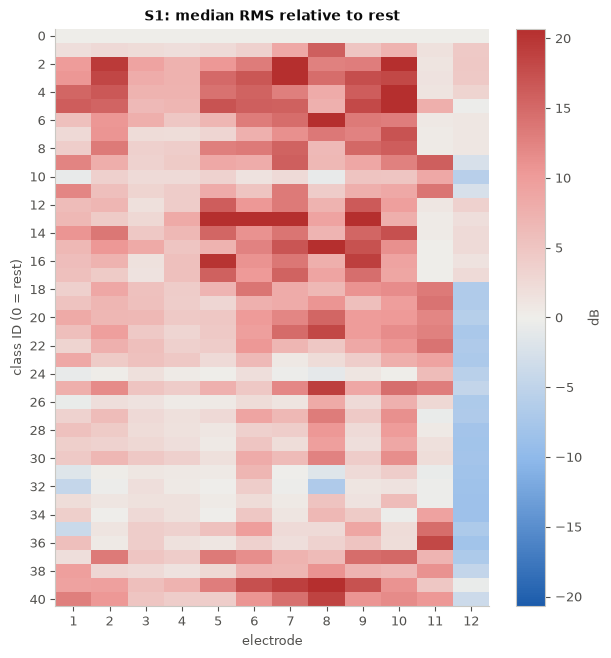

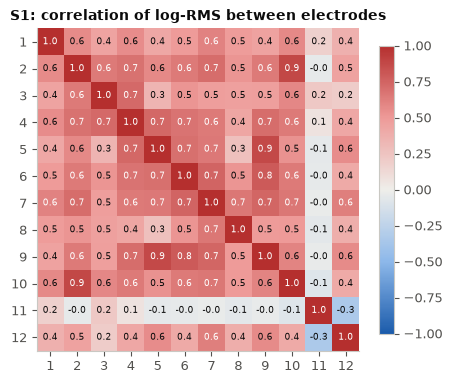

In [18]:
rms = F['emg'][:, 12:24]
rest_level = np.median(rms[M.label.values == 0], axis=0)
heat = np.vstack([np.median(rms[M.label.values == c], axis=0) - rest_level for c in range(N_CLASSES) if (M.label == c).any()])
heat = heat * 20 / np.log(10)
fig, ax = plt.subplots(figsize=(7, 7.5))
vm = np.nanpercentile(np.abs(heat), 98)
im = ax.imshow(heat, aspect='auto', cmap=DIV, vmin=-vm, vmax=vm)
ax.set_xticks(range(12), range(1, 13)); ax.set_yticks(range(0, len(heat), 2), range(0, len(heat), 2)); ax.grid(False)
ax.set(title=f'S{DETAIL}: median RMS relative to rest', xlabel='electrode', ylabel='class ID (0 = rest)')
fig.colorbar(im, ax=ax, label='dB'); savefig(fig, 'fig13_activation_map')

mv_mask = M.label.values > 0
corr = np.corrcoef(rms[mv_mask].T)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(corr, cmap=DIV, vmin=-1, vmax=1); ax.set_xticks(range(12), range(1, 13)); ax.set_yticks(range(12), range(1, 13)); ax.grid(False)
for i in range(12):
    for j in range(12):
        ax.text(j, i, f'{corr[i, j]:.1f}', ha='center', va='center', fontsize=6.5, color='white' if abs(corr[i, j]) > .6 else C['ink'])
ax.set_title(f'S{DETAIL}: correlation of log-RMS between electrodes'); fig.colorbar(im, ax=ax, shrink=.85); savefig(fig, 'fig14_channel_correlation')
off = corr[~np.eye(12, dtype=bool)]
SUMMARY.update(channel_corr_mean=float(off.mean()), channel_corr_max=float(off.max()))

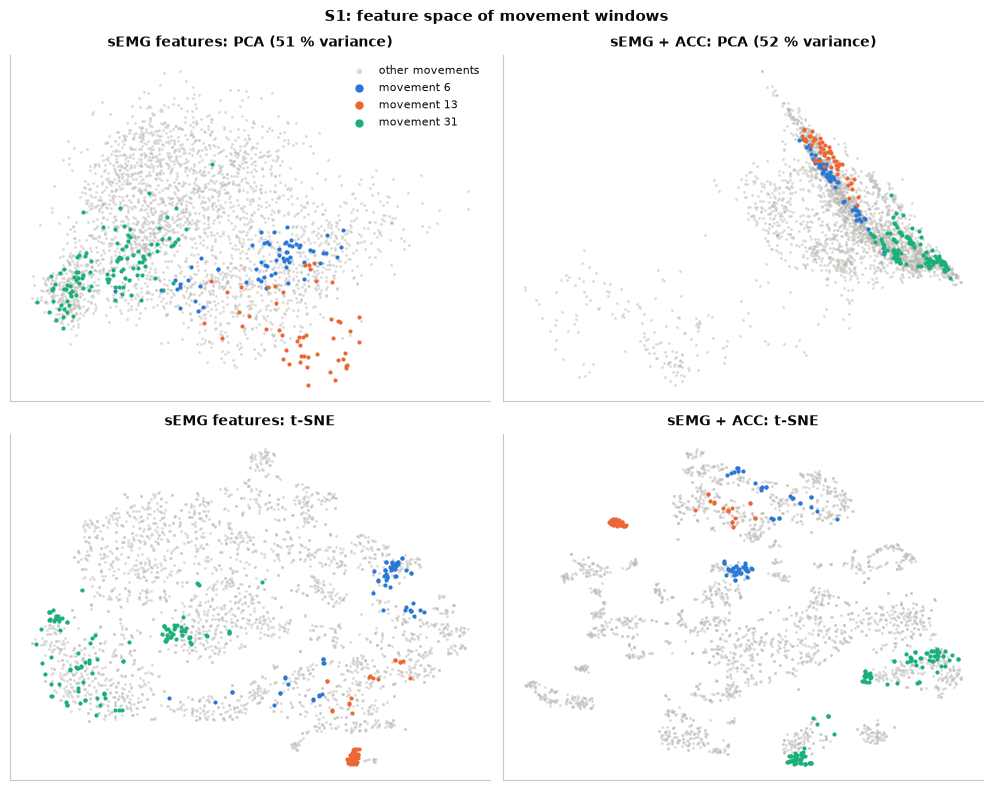

Class separability on training repetitions (higher = more separable per feature):


,modality,median_fisher_ratio,max_fisher_ratio
0,emg,1.062,4.794
1,acc,3.271,5.417
2,gyro,0.011,0.019
3,mag,8.089,18.761


In [19]:
def zfit(X, train_mask):
    sc = StandardScaler().fit(X[train_mask]); return sc.transform(X)

tr = M.rep.isin(P['train_reps']).values
rng = np.random.default_rng(P['seeds'][0])
idx = rng.choice(np.flatnonzero(mv_mask), size=min(3000, mv_mask.sum()), replace=False)
pick = [6, 13, 31]   # three example movements highlighted against all others
views = {'sEMG features': zfit(F['emg'], tr), 'sEMG + ACC': zfit(np.hstack([F['emg'], F['acc']]), tr)}
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
for j, (name, X) in enumerate(views.items()):
    pca = PCA(2, random_state=42).fit(X[tr & mv_mask])
    Z1 = pca.transform(X[idx]); Z2 = TSNE(2, random_state=42, perplexity=30, init='pca').fit_transform(PCA(min(30, X.shape[1]), random_state=42).fit_transform(X[idx]))
    for axis, Z, method in ((ax[0, j], Z1, f'PCA ({100 * pca.explained_variance_ratio_.sum():.0f} % variance)'), (ax[1, j], Z2, 't-SNE')):
        yy = M.label.values[idx]
        axis.scatter(*Z[~np.isin(yy, pick)].T, s=4, color=C['gray'], alpha=.5, label='other movements', linewidths=0)
        for c, col in zip(pick, [C['blue'], C['orange'], C['aqua']]):
            axis.scatter(*Z[yy == c].T, s=9, color=col, label=f'movement {c}', linewidths=0)
        axis.set_title(f'{name}: {method}'); axis.set_xticks([]); axis.set_yticks([])
ax[0, 0].legend(markerscale=2, fontsize=8)
fig.suptitle(f'S{DETAIL}: feature space of movement windows', fontweight='bold'); fig.tight_layout(); savefig(fig, 'fig15_feature_space')

def fisher_ratio(X, y):
    mu = X.mean(0); sb = sw = 0
    for c in np.unique(y):
        Xc = X[y == c]; sb = sb + len(Xc) * (Xc.mean(0) - mu) ** 2; sw = sw + ((Xc - Xc.mean(0)) ** 2).sum(0)
    return sb / (sw + 1e-12)

sel = tr & mv_mask     # training repetitions only
fisher = pd.DataFrame([(k, float(np.median(fisher_ratio(zfit(F[k], tr)[sel], M.label.values[sel]))),
                        float(np.max(fisher_ratio(zfit(F[k], tr)[sel], M.label.values[sel])))) for k in FEATURE_SETS],
                      columns=['modality', 'median_fisher_ratio', 'max_fisher_ratio']).round(3)
print('Class separability on training repetitions (higher = more separable per feature):')
display(savetab(fisher, 'fisher_ratio'))
SUMMARY.update(fisher_median={r.modality: float(r.median_fisher_ratio) for r in fisher.itertuples()})

### 8.1 Variation across repetitions (drift, fatigue, orientation)

,median_rms_uV,median_freq_Hz,mag_shift_from_rep1_pct
rep,,,
1,15.71,82.88,0.00
2,16.17,83.87,0.24
3,16.37,84.12,0.38
4,14.21,83.42,0.59
5,15.31,84.55,0.55
6,15.05,84.47,0.61


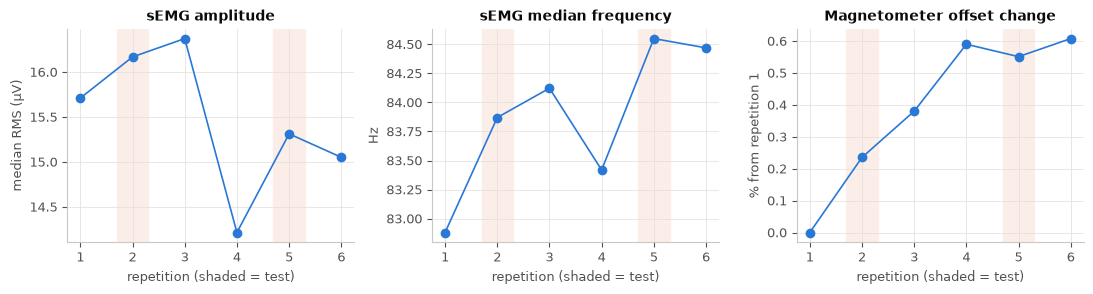

In [20]:
drift_rows = []
for (sid, ex), path in sorted(FILES.items()):
    emg = filter_columns(SOS_EMG_ALL, load(path, 'emg')[0]); mg = load(path, 'mag')[0]; lab, rep = load_labels(path); sg = segments(lab, rep)
    for r in REPS:
        s = sg[(sg[:, 2] > 0) & (sg[:, 3] == r)]
        rms_r = np.array([np.sqrt((emg[a:b] ** 2).mean(0)) for a, b in s[:, :2]])
        mdf = []
        for a, b in s[:, :2]:
            f, p = signal.welch(emg[a:b], FS, nperseg=1024, axis=0); cum = np.cumsum(p, 0) / p.sum(0)
            mdf.append(np.median([f[np.searchsorted(cum[:, c], .5)] for c in range(12)]))
        drift_rows.append(dict(subject=sid, exercise=ex, rep=r, median_rms_uV=float(np.median(rms_r) * 1e6),
                               median_freq_Hz=float(np.mean(mdf)),
                               mag_mean=np.mean([mg[a:b].mean(0) for a, b in s[:, :2]], axis=0)))
    del emg, mg; gc.collect()
D = pd.DataFrame(drift_rows)
mag_shift = []
for (sid, ex), g in D.groupby(['subject', 'exercise']):
    ref = g[g.rep == 1].mag_mean.iloc[0]
    for _, row in g.iterrows():
        mag_shift.append(float(np.linalg.norm(row.mag_mean - ref) / (np.linalg.norm(ref) + 1e-12) * 100))
D['mag_shift_from_rep1_pct'] = mag_shift
D = savetab(D.drop(columns='mag_mean'), 'repetition_drift')
dm = D.groupby('rep')[['median_rms_uV', 'median_freq_Hz', 'mag_shift_from_rep1_pct']].mean()
display(dm.round(2))
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for axis, col, ttl, yl in zip(ax, dm.columns, ['sEMG amplitude', 'sEMG median frequency', 'Magnetometer offset change'],
                              ['median RMS (µV)', 'Hz', '% from repetition 1']):
    axis.plot(dm.index, dm[col], marker='o', color=C['blue'])
    for r in P['test_reps']: axis.axvspan(r - .3, r + .3, color='#fbeee8', zorder=0)
    axis.set(title=ttl, xlabel='repetition (shaded = test)', ylabel=yl, xticks=REPS)
fig.tight_layout(); savefig(fig, 'fig16_repetition_drift')
SUMMARY.update(rms_by_rep=[float(v) for v in dm.median_rms_uV], mdf_by_rep=[float(v) for v in dm.median_freq_Hz],
               mag_shift_by_rep=[float(v) for v in dm.mag_shift_from_rep1_pct])

## 9. Export the fixed protocol and verify it

The files written here are the contract every compared model must follow.

In [21]:
man = SEG[SEG.rep.isin(REPS)].copy()
man['final_split'] = [split_of(r) for r in man.rep]            # train {1,3,4,6} / test {2,5}
man['dev_split'] = [split_of(r, dev=True) for r in man.rep]    # train {1,3,4} / val {6} / test {2,5}
w, s = P['window_ms'] * FS // 1000, P['stride_ms'] * FS // 1000
man['n_windows'] = n_windows(man.end - man.start, w, s)
man = man[['subject', 'exercise', 'label', 'rep', 'start', 'end', 'n_windows', 'dev_split', 'final_split']]
savetab(man, 'split_manifest')

checks = {}
checks['train/test repetitions disjoint'] = not set(P['train_reps']) & set(P['test_reps'])
checks['dev train/val/test disjoint and cover 1..6'] = sorted(P['dev_train_reps'] + P['val_reps'] + P['test_reps']) == list(REPS)
overlap = False
for _, g in man.sort_values('start').groupby(['subject', 'exercise']):
    overlap |= bool((g.start.values[1:] < g.end.values[:-1]).any())
checks['no sample belongs to two segments'] = not overlap
cov = man[man.label > 0].groupby(['subject', 'label', 'final_split']).rep.nunique().unstack()
checks['every movement has 4 train and 2 test repetitions'] = bool((cov['train'] == 4).all() and (cov['test'] == 2).all())
checks['every movement segment is long enough for one window'] = bool((man[man.label > 0].n_windows > 0).all())
for k, v in checks.items(): print('PASS' if v else 'FAIL', '|', k)
assert all(checks.values())

protocol = {
    'name': 'DB7-P1 intra-subject cross-repetition', 'version': '1.0',
    'dataset': {'release': 'NinaPro DB7 synchronized MAT files', 'labels': 'restimulus', 'repetitions': 'rerepetition',
                'primary_cohort': list(range(1, 21)), 'amputees_reported_separately': [21, 22],
                'classes_primary': 41, 'classes_secondary': '40 movements without rest (S21: 38)'},
    'split': {'final_train_reps': P['train_reps'], 'test_reps': P['test_reps'],
              'dev_train_reps': P['dev_train_reps'], 'val_reps': P['val_reps'], 'level': 'complete repetitions, split before windowing'},
    'windowing': {'window_ms': P['window_ms'], 'stride_ms': P['stride_ms'], 'rule': 'all samples share label and repetition'},
    'preprocessing': {'emg_bandpass_hz': P['emg_band'], 'emg_order': P['emg_order'], 'notch_hz': P['notch_hz'], 'notch_q': P['notch_q'],
                      'imu_lowpass_hz': P['imu_lowpass_hz'], 'imu_order': P['imu_order'], 'phase': 'zero-phase (offline)',
                      'normalization': 'per-subject, per-channel or per-feature z-score fitted on training repetitions only'},
    'input_sets': ['sEMG', 'sEMG+ACC', 'sEMG+ACC+gyro+mag'], 'excluded_inputs': ['glove', 'subject ID', 'exercise ID', 'repetition ID', 'time index'],
    'metrics': {'primary': 'per-window accuracy, mean ± SD over subjects, no voting',
                'secondary': ['balanced accuracy', 'macro-F1', 'majority vote (state latency)', 'parameters', 'FLOPs', 'latency per window']},
    'seeds': P['seeds'], 'statistics': 'two-sided Wilcoxon signed-rank on paired per-subject scores, Holm correction',
    'secondary_protocols': {
        'P2 leave-one-repetition-out': {'folds': 6, 'classes': 40, 'window_ms': 256, 'stride_ms': 50, 'purpose': 'comparison with Krasoulis et al. 2017'},
        'P3 amputee': {'subjects': [21, 22], 'split': 'as P1', 'purpose': 'report separately'},
        'P4 leave-one-subject-out': {'folds': 20, 'normalization': 'training subjects only', 'purpose': 'subject-independent claim'}},
}
text = json.dumps(protocol, indent=2)
(RES_DIR / 'db7_protocol.json').write_text(text)
digest = hashlib.sha256((RES_DIR / 'split_manifest.csv').read_bytes()).hexdigest()[:16]
print('Wrote db7_protocol.json and split_manifest.csv | manifest rows:', len(man), '| sha256 prefix:', digest)
SUMMARY.update(checks={k: bool(v) for k, v in checks.items()}, manifest_rows=len(man), manifest_sha256_prefix=digest)

PASS | train/test repetitions disjoint
PASS | dev train/val/test disjoint and cover 1..6
PASS | no sample belongs to two segments
PASS | every movement has 4 train and 2 test repetitions
PASS | every movement segment is long enough for one window
Wrote db7_protocol.json and split_manifest.csv | manifest rows: 480 | sha256 prefix: b1697fbc65621bb7


## 10. Sanity baselines under the fixed protocol

Purpose: confirm the pipeline works and measure how much the evaluation choices matter.
These are simple models on the available subject(s); they are **not** a proposed method and not a DB7
cohort result unless all 20 intact subjects are present.

In [22]:
def scores(y, p):
    return dict(accuracy=100 * accuracy_score(y, p), balanced_accuracy=100 * balanced_accuracy_score(y, p),
                macro_f1=100 * f1_score(y, p, average='macro', zero_division=0))

def lda():
    return LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto')

def fit_eval(X, y, itr, ite, model):
    sc = StandardScaler().fit(X[itr])
    model.fit(sc.transform(X[itr]), y[itr])
    pred = model.predict(sc.transform(X[ite]))
    return scores(y[ite], pred), pred

INPUTS = {'sEMG': ('emg',), 'sEMG+ACC': ('emg', 'acc'), 'sEMG+ACC+gyro+mag': ('emg', 'acc', 'gyro', 'mag')}
base_rows = []; cm_keep = None
for sid in SUBJECTS:
    Fs, Ms = subject_features(sid, P['window_ms'], P['stride_ms'])
    y = Ms.label.values; itr = Ms.rep.isin(P['train_reps']).values; ite = Ms.rep.isin(P['test_reps']).values
    assert not (itr & ite).any()
    maj = np.bincount(y[itr]).argmax()
    base_rows.append(dict(subject=sid, task='41 classes', inputs='none (always predict majority class)', model='majority',
                          n_train=int(itr.sum()), n_test=int(ite.sum()), **scores(y[ite], np.full(ite.sum(), maj))))
    for name, kinds in INPUTS.items():
        X = np.hstack([Fs[k] for k in kinds])
        for task, keep in (('41 classes', np.ones(len(y), bool)), ('40 classes (no rest)', y > 0)):
            res, pred = fit_eval(X, y, itr & keep, ite & keep, lda())
            base_rows.append(dict(subject=sid, task=task, inputs=name, model='LDA', n_train=int((itr & keep).sum()), n_test=int((ite & keep).sum()), **res))
            if sid == DETAIL and name == 'sEMG+ACC' and task == '41 classes':
                cm_keep = confusion_matrix(y[ite], pred, labels=np.arange(41), normalize='true')
    del Fs, Ms; gc.collect()
BASE = savetab(pd.DataFrame(base_rows), 'baseline_protocol_P1')
display(BASE.round(2))

,subject,task,inputs,model,n_train,n_test,accuracy,balanced_accuracy,macro_f1
0,1,41 classes,none (always predict majority class),majority,140674,66261,51.48,2.44,1.66
1,1,41 classes,sEMG,LDA,140674,66261,77.62,62.78,63.92
2,1,40 classes (no rest),sEMG,LDA,65187,32152,68.59,69.10,69.40
3,1,41 classes,sEMG+ACC,LDA,140674,66261,85.15,78.90,79.92
4,1,40 classes (no rest),sEMG+ACC,LDA,65187,32152,87.23,86.68,87.09
5,1,41 classes,sEMG+ACC+gyro+mag,LDA,140674,66261,86.82,85.34,85.12
6,1,40 classes (no rest),sEMG+ACC+gyro+mag,LDA,65187,32152,95.28,94.88,95.24


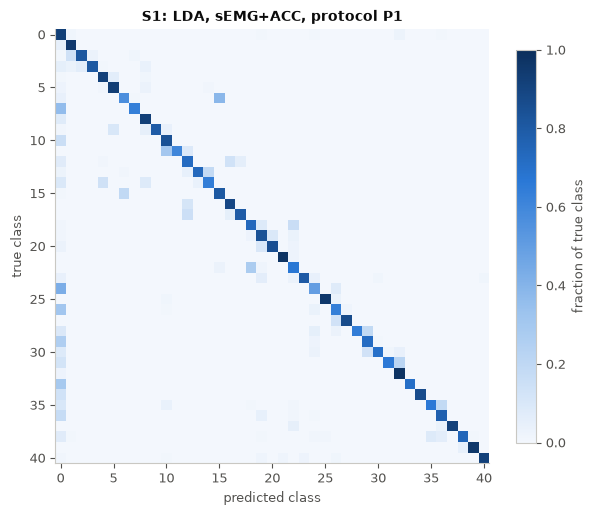

Most frequent movement-to-movement confusions:


,true_movement,predicted_movement,pct_of_true
0,6,15,38.6
1,11,10,30.5
2,22,18,27.6
3,31,32,21.8
4,15,6,18.8
5,28,29,18.7
6,35,36,18.7
7,13,14,18.0


In [23]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_keep, cmap=SEQ, vmin=0, vmax=1); ax.grid(False)
ax.set(title=f'S{DETAIL}: LDA, sEMG+ACC, protocol P1', xlabel='predicted class', ylabel='true class')
fig.colorbar(im, ax=ax, shrink=.85, label='fraction of true class'); savefig(fig, 'fig17_confusion_lda')
recall = pd.Series(np.diag(cm_keep), name='recall')
off_cm = cm_keep.copy(); np.fill_diagonal(off_cm, 0)
pairs = sorted([(off_cm[i, j], i, j) for i in range(1, 41) for j in range(1, 41) if i != j], reverse=True)[:8]
hard = pd.DataFrame([(i, j, round(100 * v, 1)) for v, i, j in pairs], columns=['true_movement', 'predicted_movement', 'pct_of_true'])
print('Most frequent movement-to-movement confusions:'); display(savetab(hard, 'top_confusions'))

### 10.1 Why the split must be made on whole repetitions

Same subject, same features, same classifiers, same test fraction (1/3). Only the split rule changes:
**random windows** (overlapping neighbours land in both sets) versus **held-out repetitions**.

,model,split,n_train,n_test,accuracy,balanced_accuracy,macro_f1
0,LDA,random windows,27718,13859,85.40,78.51,80.27
1,LDA,held-out repetitions,28262,13315,84.23,77.40,78.48
2,1-nearest neighbour,random windows,27718,13859,99.12,98.96,98.99
3,1-nearest neighbour,held-out repetitions,28262,13315,81.01,76.15,75.61
4,ExtraTrees (60 trees),random windows,27718,13859,97.42,95.48,97.24
5,ExtraTrees (60 trees),held-out repetitions,28262,13315,86.98,84.07,85.78


Random split: 100.0 % of test windows come from a repetition that also supplied training windows.


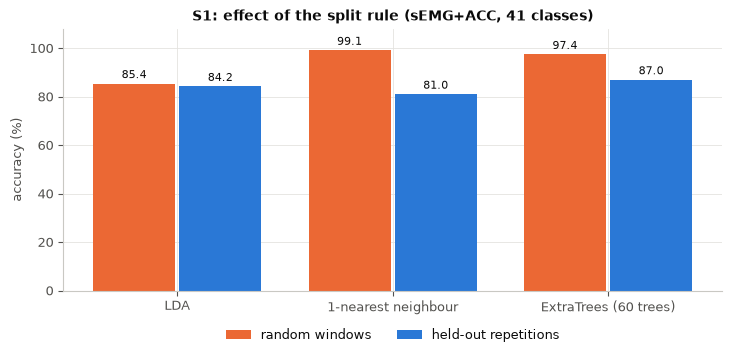

In [24]:
y = M.label.values
X = np.hstack([F['emg'], F['acc']])          # 200 ms windows, 50 ms stride (75 % overlap)
rep_tr = np.flatnonzero(M.rep.isin(P['train_reps'])); rep_te = np.flatnonzero(M.rep.isin(P['test_reps']))
rnd_tr, rnd_te = train_test_split(np.arange(len(y)), test_size=1 / 3, stratify=y, random_state=42)
leak_rows = []
for mname, make in (('LDA', lda), ('1-nearest neighbour', lambda: KNeighborsClassifier(1, n_jobs=-1)),
                    ('ExtraTrees (60 trees)', lambda: ExtraTreesClassifier(60, random_state=42, n_jobs=-1, min_samples_leaf=2))):
    for sname, (a_, b_) in (('random windows', (rnd_tr, rnd_te)), ('held-out repetitions', (rep_tr, rep_te))):
        res, _ = fit_eval(X, y, a_, b_, make())
        leak_rows.append(dict(model=mname, split=sname, n_train=len(a_), n_test=len(b_), **res))
        gc.collect()
LEAK = savetab(pd.DataFrame(leak_rows), 'leakage_experiment')
display(LEAK.round(2))
key = list(zip(M.exercise, M.segment_start))
shared = np.mean(pd.Series([key[i] for i in rnd_te]).isin(set(key[i] for i in rnd_tr)))
print(f'Random split: {100 * shared:.1f} % of test windows come from a repetition that also supplied training windows.')
fig, ax = plt.subplots(figsize=(8.5, 3.4))
models = LEAK.model.unique(); x = np.arange(len(models))
for off_, sname, col in ((-.2, 'random windows', C['orange']), (.2, 'held-out repetitions', C['blue'])):
    v = LEAK[LEAK.split == sname].set_index('model').loc[models].accuracy
    bars = ax.bar(x + off_, v, .38, color=col, label=sname)
    ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=8)
ax.set_xticks(x, models); ax.set(ylim=(0, 108), ylabel='accuracy (%)', title=f'S{DETAIL}: effect of the split rule (sEMG+ACC, 41 classes)')
ax.legend(ncol=2, loc='upper center', bbox_to_anchor=(.5, -.1)); savefig(fig, 'fig18_leakage')
piv = LEAK.pivot(index='model', columns='split', values='accuracy')
SUMMARY.update(leakage={m: dict(random=float(piv.loc[m, 'random windows']), repetition=float(piv.loc[m, 'held-out repetitions'])) for m in piv.index},
               leak_shared_pct=float(100 * shared))

### 10.2 Window length

,window_ms,inputs,n_test,accuracy,balanced_accuracy,macro_f1
0,100,sEMG,13635,74.54,57.14,58.18
1,100,sEMG+ACC,13635,82.46,74.94,75.98
2,150,sEMG,13475,76.22,60.05,61.16
3,150,sEMG+ACC,13475,83.47,76.49,77.52
4,200,sEMG,13315,77.35,62.15,63.28
5,200,sEMG+ACC,13315,84.23,77.40,78.48
6,250,sEMG,13155,78.42,64.10,65.33
7,250,sEMG+ACC,13155,84.87,78.34,79.47
8,300,sEMG,12995,79.26,65.58,66.83
9,300,sEMG+ACC,12995,85.41,79.19,80.32


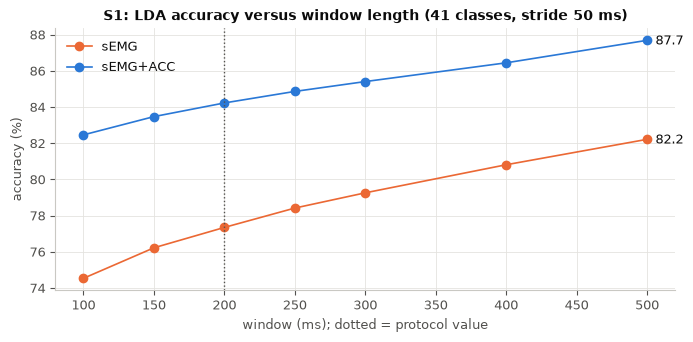

In [25]:
win_rows = []
for wl in (100, 150, 200, 250, 300, 400, 500):
    Fw, Mw = subject_features(DETAIL, wl, 50, kinds=('emg', 'acc'))
    yw = Mw.label.values; itr = Mw.rep.isin(P['train_reps']).values; ite = Mw.rep.isin(P['test_reps']).values
    for name, kinds in (('sEMG', ('emg',)), ('sEMG+ACC', ('emg', 'acc'))):
        res, _ = fit_eval(np.hstack([Fw[k] for k in kinds]), yw, itr, ite, lda())
        win_rows.append(dict(window_ms=wl, inputs=name, n_test=int(ite.sum()), **res))
    del Fw, Mw; gc.collect()
WIN = savetab(pd.DataFrame(win_rows), 'window_length_sweep')
display(WIN.round(2))
fig, ax = plt.subplots(figsize=(8, 3.4))
for name, col in (('sEMG', C['orange']), ('sEMG+ACC', C['blue'])):
    g = WIN[WIN.inputs == name]; ax.plot(g.window_ms, g.accuracy, marker='o', color=col, label=name)
    ax.annotate(f'{g.accuracy.iloc[-1]:.1f}', (g.window_ms.iloc[-1], g.accuracy.iloc[-1]), xytext=(6, -3), textcoords='offset points')
ax.axvline(200, color=C['ink2'], ls=':', lw=1)
ax.set(title=f'S{DETAIL}: LDA accuracy versus window length (41 classes, stride 50 ms)', xlabel='window (ms); dotted = protocol value', ylabel='accuracy (%)')
ax.legend(); savefig(fig, 'fig19_window_length')

## 11. Summary

In [26]:
b = BASE[BASE.model == 'LDA'].groupby(['task', 'inputs'])[['accuracy', 'balanced_accuracy', 'macro_f1']].mean().round(2)
display(b)
SUMMARY['baseline_P1'] = [dict(task=t, inputs=i, **{k: float(v) for k, v in r.items()}) for (t, i), r in b.iterrows()]
SUMMARY['majority_accuracy'] = float(BASE[BASE.model == 'majority'].accuracy.mean())
(RES_DIR / 'summary.json').write_text(json.dumps(SUMMARY, indent=2, default=float))
print(f"Subjects analysed: {SUBJECTS}")
print(f"Recorded time: {SUMMARY['minutes_total']:.1f} min | rest share: {SUMMARY['rest_pct']:.1f} % | non-finite values: {SUMMARY['nonfinite']}")
print(f"Median label onset lag: {SUMMARY['onset_lag_median_s']:.2f} s | label disagreement: {SUMMARY['label_disagreement_pct']:.1f} % of samples")
print(f"Activation SNR: {SUMMARY['snr_db_min']:.1f} to {SUMMARY['snr_db_max']:.1f} dB | median frequency (movement): {SUMMARY['median_freq_move_Hz']:.0f} Hz")
print(f"Protocol windows (200/10 ms): train {SUMMARY['windows_train']:,} (dev), val {SUMMARY['windows_val']:,}, test {SUMMARY['windows_test']:,}")
print('Figures:', len(list(FIG_DIR.glob('fig*.png'))), '| tables:', len(list(RES_DIR.glob('*.csv'))))

accuracy  balanced_accuracy  macro_f1
task                 inputs                                                  
40 classes (no rest) sEMG                  68.59              69.10     69.40
                     sEMG+ACC              87.23              86.68     87.09
                     sEMG+ACC+gyro+mag     95.28              94.88     95.24
41 classes           sEMG                  77.62              62.78     63.92
                     sEMG+ACC              85.15              78.90     79.92
                     sEMG+ACC+gyro+mag     86.82              85.34     85.12

Subjects analysed: [1]
Recorded time: 36.1 min | rest share: 52.9 % | non-finite values: 0
Median label onset lag: 0.75 s | label disagreement: 18.5 % of samples
Activation SNR: -1.7 to 12.1 dB | median frequency (movement): 81 Hz
Protocol windows (200/10 ms): train 106,831 (dev), val 33,843, test 66,261
Figures: 19 | tables: 20
